# Experiment Three

Read the dataset from the user. Use Find S algorithm to find the most specific hypothesis consistent with the positive examples. State the final hypothesis afer processing all positive exampes

In [4]:


data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']
]

def find_s(dataset):
    hypothesis = None
    for row in dataset:
        if row[-1] == 'Yes':
            hypothesis = list(row[:-1])
            break

    for row in dataset:
        if row[-1] == 'Yes':
            for i in range(len(hypothesis)):
                if row[i] != hypothesis[i]:
                    hypothesis[i] = '?'
    return hypothesis

result = find_s(data)
print("Final Hypothesis:", result)

Final Hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


Initial Hypothesis: ['0', '0', '0', '0']

Positive Example - Evaluating: ['High', 'Good', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['High', 'Good', 'Many', 'Good']

Positive Example - Evaluating: ['Medium', 'Good', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['?', 'Good', 'Many', 'Good']

Negative Example - Skipped: ['Low', 'Poor', 'None', 'Poor', 'No']
Positive Example - Evaluating: ['High', 'Average', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['?', '?', 'Many', 'Good']

Negative Example - Skipped: ['Medium', 'Poor', 'Few', 'Average', 'No']
Positive Example - Evaluating: ['High', 'Good', 'Few', 'Good', 'Yes']
Updated Hypothesis: ['?', '?', '?', 'Good']

Final Hypothesis: ['?', '?', '?', 'Good']


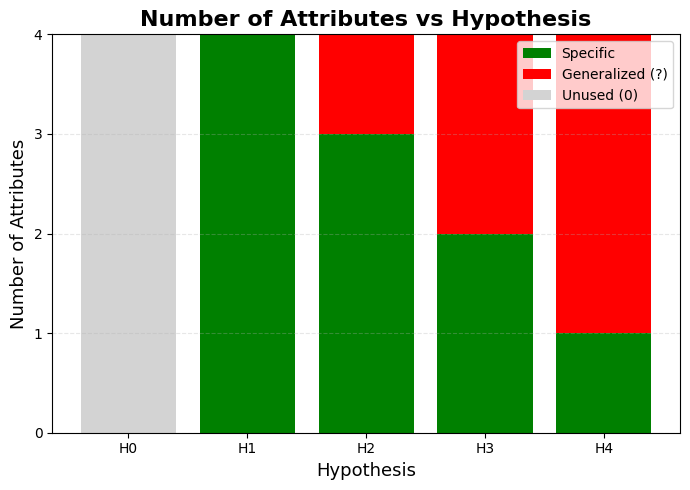

In [6]:
# Find-S Algorithm

import matplotlib.pyplot as plt


dataset = [
    ["High", "Good", "Many", "Good", "Yes"],
    ["Medium", "Good", "Many", "Good", "Yes"],
    ["Low", "Poor", "None", "Poor", "No"],
    ["High", "Average", "Many", "Good", "Yes"],
    ["Medium", "Poor", "Few", "Average", "No"],
    ["High", "Good", "Few", "Good", "Yes"]
]


attributes = dataset[0][:-1]

hypothesis = ["0"] * len(attributes)

history = []

print("Initial Hypothesis:", hypothesis)
print()


for example in dataset:

    example_attributes = example[:-1]
    target = example[-1]

    if target == "No":

        print("Negative Example - Skipped:", example)
        continue

    print("Positive Example - Evaluating:", example)

    if hypothesis[0] == "0":

        hypothesis = example_attributes.copy()

    else:

        for i in range(len(hypothesis)):

            if hypothesis[i] != example_attributes[i]:

                hypothesis[i] = "?"

    history.append(hypothesis.copy())

    print("Updated Hypothesis:", hypothesis)
    print()



print("Final Hypothesis:", hypothesis)

all_hypotheses = [["0"] * len(attributes)] + history

# Create labels H0, H1, H2, ...
hypothesis_labels = [
    f"H{i}" for i in range(len(all_hypotheses))
]

# Count attributes of each type
unused_counts = []
specific_counts = []
generalized_counts = []

for hypothesis in all_hypotheses:

    unused = hypothesis.count("0")
    generalized = hypothesis.count("?")
    specific = len(hypothesis) - unused - generalized

    unused_counts.append(unused)
    specific_counts.append(specific)
    generalized_counts.append(generalized)
plt.figure(figsize=(7, 5))

# Specific attributes
plt.bar(
    hypothesis_labels,
    specific_counts,
    color="green",
    label="Specific"
)

# Generalized attributes
plt.bar(
    hypothesis_labels,
    generalized_counts,
    bottom=specific_counts,
    color="red",
    label="Generalized (?)"
)

# Unused attributes
bottom_unused = [
    specific_counts[i] + generalized_counts[i]
    for i in range(len(hypothesis_labels))
]

plt.bar(
    hypothesis_labels,
    unused_counts,
    bottom=bottom_unused,
    color="lightgray",
    label="Unused (0)"
)
plt.title(
    "Number of Attributes vs Hypothesis",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Hypothesis",
    fontsize=13
)

plt.ylabel(
    "Number of Attributes",
    fontsize=13
)

plt.legend()

# Y-axis should represent number of attributes
plt.yticks(range(0, len(attributes) + 1))

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()